Model Accuracy: 82.1255699754472 %
Win/Loss Probability: [0.03626234 0.96373766]
       end_of_over  runs_after_over  wickets_in_over  lose   win
10459            1              4.0              0.0  59.5  40.5
10467            2              8.0              0.0  56.2  43.8
10473            3              1.0              0.0  59.3  40.7
10479            4              7.0              0.0  68.9  31.1
10485            5             12.0              0.0  61.5  38.5
10491            6             13.0              0.0  52.1  47.9
10497            7              9.0              0.0  47.0  53.0
10505            8             15.0              0.0  34.9  65.1
10511            9              7.0              0.0  32.4  67.6
10518           10             17.0              0.0  20.2  79.8
10524           11              9.0              1.0  25.2  74.8
10530           12              9.0              0.0  21.1  78.9
10536           13              8.0              0.0  18.4  81.6
10542    

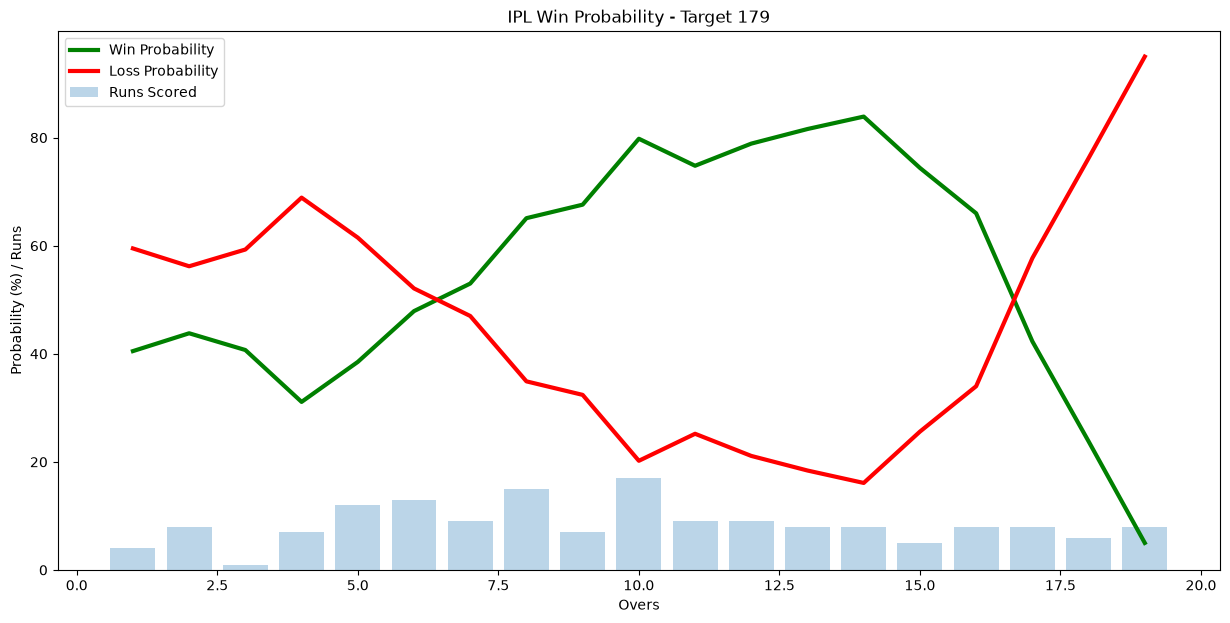

Model saved successfully!


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score



match = pd.read_csv("matches.csv")
delivery = pd.read_csv("deliveries.csv")

score = delivery[delivery["inning"] == 1].groupby("match_id")[
    "total_runs"
].sum().reset_index()

score["total_runs"] = score["total_runs"] + 1

match = match.merge(score, left_on="id", right_on="match_id")



teams = [
    "Sunrisers Hyderabad", "Mumbai Indians",
    "Royal Challengers Bangalore", "Kolkata Knight Riders",
    "Kings XI Punjab", "Chennai Super Kings",
    "Rajasthan Royals", "Delhi Capitals"
]

match["team1"] = match["team1"].replace({
    "Delhi Daredevils": "Delhi Capitals",
    "Deccan Chargers": "Sunrisers Hyderabad"
})

match["team2"] = match["team2"].replace({
    "Delhi Daredevils": "Delhi Capitals",
    "Deccan Chargers": "Sunrisers Hyderabad"
})

delivery["batting_team"] = delivery["batting_team"].replace({
    "Delhi Daredevils": "Delhi Capitals",
    "Deccan Chargers": "Sunrisers Hyderabad"
})

delivery["bowling_team"] = delivery["bowling_team"].replace({
    "Delhi Daredevils": "Delhi Capitals",
    "Deccan Chargers": "Sunrisers Hyderabad"
})

match = match[
    match["team1"].isin(teams) & match["team2"].isin(teams)
]

match = match[match["dl_applied"] == 0]

match = match[["match_id", "city", "winner", "total_runs"]]


# 4. Merge second innings data
df = match.merge(delivery, on="match_id")
df = df[df["inning"] == 2].copy()

df = df.sort_values(["match_id", "over", "ball"])



df["current_score"] = df.groupby("match_id")["total_runs_y"].cumsum()

df["runs_left"] = df["total_runs_x"] - df["current_score"]

df["balls_left"] = 120 - (
    (df["over"] - 1) * 6 + df["ball"]
)

df["player_dismissed"] = df["player_dismissed"].notna().astype(int)

df["wickets"] = 10 - df.groupby("match_id")["player_dismissed"].cumsum()

df["crr"] = (
    df["current_score"] * 6 /
    (120 - df["balls_left"]).replace(0, np.nan)
)

df["rrr"] = (
    df["runs_left"] * 6 /
    df["balls_left"].replace(0, np.nan)
)

df["result"] = (df["batting_team"] == df["winner"]).astype(int)


#PREPARE FINAL DATASET
final_df = df[[
    "match_id", "batting_team", "bowling_team", "city",
    "runs_left", "balls_left", "wickets",
    "total_runs_x", "crr", "rrr", "result"
]].copy()

final_df = final_df.replace([np.inf, -np.inf], np.nan).dropna()

final_df = final_df[final_df["balls_left"] > 0]

final_df = final_df.sample(frac=1, random_state=42)

X = final_df[[
    "batting_team", "bowling_team", "city",
    "runs_left", "balls_left", "wickets",
    "total_runs_x", "crr", "rrr"
]]

y = final_df["result"]


#SPLIT DATA
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)


#ENCODE TEAM NAMES AND CITY
trf = ColumnTransformer([
    ("encoder", OneHotEncoder(
        handle_unknown="ignore", drop="first"
    ), ["batting_team", "bowling_team", "city"])
], remainder="passthrough")


#TRAIN MODEL
pipe = Pipeline([
    ("step1", trf),
    ("step2", LogisticRegression(solver="liblinear", max_iter=1000))
])

pipe.fit(X_train, y_train)


#CHECK ACCURACY
y_pred = pipe.predict(X_test)

print("Model Accuracy:", accuracy_score(y_test, y_pred) * 100, "%")

print("Win/Loss Probability:", pipe.predict_proba(X_test.iloc[[10]])[0])


# 11MATCH PROGRESSION
def match_progression(data, match_id, model):

    temp = data[
        (data["match_id"] == match_id) & (data["ball"] == 6)
    ].copy()

    temp = temp[temp["balls_left"] > 0]

    features = [
        "batting_team", "bowling_team", "city",
        "runs_left", "balls_left", "wickets",
        "total_runs_x", "crr", "rrr"
    ]

    probability = model.predict_proba(temp[features])

    temp["lose"] = np.round(probability[:, 0] * 100, 1)
    temp["win"] = np.round(probability[:, 1] * 100, 1)

    temp["end_of_over"] = temp["over"]

    temp["runs_after_over"] = (
        temp["current_score"].diff().fillna(temp["current_score"])
    )

    temp["wickets_in_over"] = (
        temp["player_dismissed"].groupby(temp["match_id"]).cumsum().diff().fillna(
            temp["player_dismissed"]
        )
    )

    target = temp["total_runs_x"].iloc[0]

    return temp[[
        "end_of_over", "runs_after_over",
        "wickets_in_over", "lose", "win"
    ]], target


#CHOOSE A MATCH ID FROM YOUR DATASET
match_id = 74

temp_df, target = match_progression(df, match_id, pipe)

print(temp_df)


#PLOT GRAPH
plt.figure(figsize=(15, 7))

plt.plot(temp_df["end_of_over"], temp_df["win"],
         color="green", linewidth=3, label="Win Probability")

plt.plot(temp_df["end_of_over"], temp_df["lose"],
         color="red", linewidth=3, label="Loss Probability")

plt.bar(temp_df["end_of_over"], temp_df["runs_after_over"],
        alpha=0.3, label="Runs Scored")

plt.title("IPL Win Probability - Target " + str(target))
plt.xlabel("Overs")
plt.ylabel("Probability (%) / Runs")
plt.legend()
plt.show()


#SAVE MODEL
pickle.dump(pipe, open("pipe.pkl", "wb"))

print("Model saved successfully!")


In [3]:
teams

['Sunrisers Hyderabad',
 'Mumbai Indians',
 'Royal Challengers Bangalore',
 'Kolkata Knight Riders',
 'Kings XI Punjab',
 'Chennai Super Kings',
 'Rajasthan Royals',
 'Delhi Capitals']

In [5]:

import pickle

with open("pipe.pkl", "rb") as file:
    model = pickle.load(file)

print("Model loaded successfully!")
print(model)

print(temp_df)



Model loaded successfully!
Pipeline(steps=[('step1',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('encoder',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['batting_team',
                                                   'bowling_team', 'city'])])),
                ('step2',
                 LogisticRegression(max_iter=1000, solver='liblinear'))])


NameError: name 'temp_df' is not defined